# ABS 挑戰時機研究：逐頁重現簡報數字

隊名：**志在參加**

這份 notebook 依簡報頁碼，把每一頁用到的數字從資料重新算出來，並和簡報上的寫法並列。
每一個 `check(...)` 會印出「簡報寫的值」和「重算的值」，最後一節彙整成一張對照表。

**使用方式**

1. 安裝套件：`pip install -r requirements.txt`（另需 `jupyter`）。
2. 第一次使用（沒有任何資料）：把下面設定格的 `RUN_FETCH`、`RUN_PIPELINE` 都改成 `True`，從頭執行。
   會先從 Baseball Savant 與 MLB Stats API 下載資料（約 40–60 分鐘），再跑完整分析（約 3–5 分鐘）。
3. 已經有 `data/processed/` 的中間檔：維持預設（全部 `False`），直接逐頁核對。
4. `RUN_BOOT=True` 會重跑 bootstrap（約 1 小時）。預設使用 repo 內附的 `outputs/tables/dp_boot_*.csv`、`ro_boot_*.csv`。

若已經在別的資料夾下載過 Statcast 月檔，可設環境變數 `ABS_STATCAST_DIR` 指向該資料夾，跳過下載。

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import norm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import (  # noqa: E402
    CALLS_G, FIG, NODES_OPT, OPPS, PA, PERCEPTION, POLICY_VALUES, STATCAST_DIR, STATCAST_GLOB, TAB, WE_MODEL,
)

# ---- 設定 ----
RUN_FETCH = False     # True：下載 Statcast（00）與 MLB Stats API playByPlay（01）
RUN_PIPELINE = False  # True：重跑 02–14 全部分析步驟
RUN_BOOT = False      # True：連 bootstrap 一起重跑（約 1 小時）

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("專案根目錄：", ROOT.name)
print("Statcast 資料夾：", "由環境變數 ABS_STATCAST_DIR 指定" if os.environ.get("ABS_STATCAST_DIR") else STATCAST_DIR.relative_to(ROOT))


def run(script: str, *args) -> None:
    """在專案根目錄執行 scripts/ 底下的一支步驟腳本，印出最後的輸出。"""
    cmd = [sys.executable, f"scripts/{script}", *map(str, args)]
    print("$ python", " ".join(cmd[1:]))
    t = time.time()
    r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    print(r.stdout[-2500:])
    if r.returncode:
        print(r.stderr[-2500:])
        raise RuntimeError(f"{script} 失敗")
    print(f"（{time.time() - t:.0f} 秒）\n")


CHECKS: list[dict] = []


def check(page: int, item: str, slide: str, value, fmt: str = "{:.2f}") -> None:
    """記錄一個數字：簡報上的寫法 vs. 重算值（依 fmt 格式化成和簡報相同的位數）。"""
    s = fmt.format(value)
    ok = "✓" if s.replace(",", "") == str(slide).replace(",", "") else "≈"
    CHECKS.append(dict(頁=page, 項目=item, 簡報=slide, 重算=s, 一致=ok))
    print(f"[第 {page} 頁] {item}：簡報 {slide}｜重算 {s} {ok}")


def T(name: str) -> pd.DataFrame:
    """讀 outputs/tables 底下的結果表。"""
    return pd.read_csv(TAB / f"{name}.csv")


def show_fig(name: str) -> None:
    """在 notebook 裡顯示 outputs/figures 底下的圖（純 Python 執行時略過）。"""
    try:
        from IPython.display import Image, display

        if (FIG / name).exists():
            display(Image(filename=str(FIG / name), width=900))
    except ImportError:
        pass


PCT = "{:.0%}"
PCT1 = "{:.1%}"

專案根目錄： abs_challenge_github
Statcast 資料夾： 由環境變數 ABS_STATCAST_DIR 指定


## 0. 取得資料與執行分析

步驟對應（詳見 README）：00 Statcast → 01 playByPlay → 02 挑戰紀錄 → 03 合併與重判 → 04 勝率模型（G）
→ 05 判斷誤差模型（p）→ 06 動態規劃（C）與策略模擬 → 07 門檻卡、實際 vs 最佳、各隊 → 09 斷點迴歸
→ 10、11 穩健性檢查 → 12 與 Savant 核對 → 13 簡報補充表 → 08、14 圖。

In [2]:
if RUN_FETCH:
    run("00_fetch_statcast.py")
    run("01_fetch_feed.py")

if RUN_PIPELINE:
    run("02_build_challenges.py")
    run("03_build_opportunities.py")
    for p in ["fit", "valid", "gain"]:
        run("04_win_expectancy.py", "--part", p)
    run("05_perception.py")
    run("06_option_value.py", "--iters", 60)
    run("06_option_value.py", "--sens")
    if RUN_BOOT:
        for s in range(0, 200, 25):
            run("06_option_value.py", "--boot", s, 25)
    for p in ["card", "h2", "forward", "teams"]:
        run("07_analysis.py", "--part", p)
    run("09_rd.py")
    for p in ["path", "state", "rd"]:
        run("10_count_checks.py", "--part", p)
    run("11_runs_objective.py")
    if RUN_BOOT:
        for s in (0, 50):
            run("11_runs_objective.py", "--boot", s, 50)
        run("11_runs_objective.py", "--summary")
    run("12_savant_check.py")
    run("13_slide_extras.py")
    run("08_figures.py")
    run("14_slide_figures.py")

need = [CALLS_G, OPPS, NODES_OPT, PERCEPTION, WE_MODEL, PA, POLICY_VALUES]
missing = [p.name for p in need if not p.exists()]
if missing:
    raise FileNotFoundError(f"缺少中間檔 {missing}：請把 RUN_FETCH、RUN_PIPELINE 設為 True 後重跑上一格")
HAS_STATCAST = any(STATCAST_DIR.glob(STATCAST_GLOB))
print("中間檔齊全。Statcast 原始檔：", "有" if HAS_STATCAST else "沒有（第 9、10、12、15 頁有幾個數字會略過）")

中間檔齊全。Statcast 原始檔： 有


## 共用資料

- `calls`：全季 371,386 顆主審判決的球（每列一球），含重判結果、剩餘挑戰次數、改判收益 G
- `opps`：其中「被判不利、且手上還有挑戰次數」的挑戰機會
- `nodes`：動態規劃的決策點，含失敗代價 C1／C2 與最佳挑戰機率

In [3]:
calls = pd.read_parquet(CALLS_G)
opps = pd.read_parquet(OPPS)
nodes = pd.read_parquet(NODES_OPT)
ch = calls[calls.challenged.astype(bool)].copy()
ch["overturned"] = ch.overturned.astype(float)
n_games = calls.game_pk.nunique()
print(f"判決球 {len(calls):,}、挑戰機會 {len(opps):,}、決策點 {len(nodes):,}、比賽 {n_games:,} 場")

判決球 371,386、挑戰機會 345,358、決策點 371,379、比賽 2,429 場


## 第 4 頁｜2026 年 MLB 現況

In [4]:
check(4, "全季挑戰次數", "10,558", len(ch), "{:,}")
check(4, "每隊每場挑戰", "2.2", len(ch) / (n_games * 2), "{:.1f}")
check(4, "挑戰成功率", "54%", ch.overturned.mean(), PCT)
role = ch.groupby("chal_role").overturned.mean()
print("各位置成功率（本研究資料；簡報引用 Baseball-Reference 的 59/49/40%）：", role.round(3).to_dict())
miss = opps[opps.m > 0]
check(4, "主審判錯的挑戰機會", "22,623", len(miss), "{:,}")
check(4, "判錯的球實際被挑戰", "25%", miss.challenged.mean(), PCT)
check(4, "被挑戰的球占判決球", "3%", len(ch) / len(calls), PCT)
check(4, "誤判不到 1 英吋", "61%", (miss.m < 1).mean(), PCT)
# 最佳策略下，這些判錯的球被挑戰的比例：決策點上的最佳挑戰機率（剩 2 次用 q2、剩 1 次用 q1）取平均
mm = nodes[(nodes.m > 0) & (nodes.rem_eligible > 0)]
q_opt = np.where(mm.rem_eligible == 2, mm.q2, mm.q1)
check(4, "最佳策略會挑戰的比例", "37%", q_opt.mean(), PCT)

[第 4 頁] 全季挑戰次數：簡報 10,558｜重算 10,558 ✓
[第 4 頁] 每隊每場挑戰：簡報 2.2｜重算 2.2 ✓
[第 4 頁] 挑戰成功率：簡報 54%｜重算 54% ✓
各位置成功率（本研究資料；簡報引用 Baseball-Reference 的 59/49/40%）： {'batter': 0.488, 'catcher': 0.586, 'pitcher': 0.397}
[第 4 頁] 主審判錯的挑戰機會：簡報 22,623｜重算 22,623 ✓
[第 4 頁] 判錯的球實際被挑戰：簡報 25%｜重算 25% ✓
[第 4 頁] 被挑戰的球占判決球：簡報 3%｜重算 3% ✓
[第 4 頁] 誤判不到 1 英吋：簡報 61%｜重算 61% ✓
[第 4 頁] 最佳策略會挑戰的比例：簡報 37%｜重算 37% ✓


## 第 6 頁｜Savant 的公式

「得分價值」＝判壞球後的得分期望值 − 判好球後的得分期望值（`dRE`，由 04 的 RE288 算出）。

In [5]:
sv = T("savant_compare_summary").set_index("metric")
check(6, "每次改判平均得分（本研究）", "0.192", sv.loc["runs_gained per overturn（打擊）", "ours_sum"], "{:.3f}")
check(6, "每次改判平均得分（Savant）", "0.189", sv.loc["runs_gained per overturn（打擊）", "savant_sum"], "{:.3f}")
cnt = calls.balls_pre.astype(str) + "-" + calls.strikes_pre.astype(str)
ex1 = calls[(calls.outs_when_up == 0) & (calls.bases == 0) & (cnt == "0-0")].dRE.mean()
ex2 = calls[(calls.outs_when_up == 2) & (calls.bases == 7) & (cnt == "3-2")].dRE.mean()
check(6, "例一：0 出局無人 0-0 的得分價值", "0.079", ex1, "{:.3f}")
check(6, "例一門檻 0.2÷(0.2+0.079)", "72%", 0.2 / (0.2 + ex1), PCT)
check(6, "例二：2 出局滿壘 3-2 的得分價值", "1.76", ex2, "{:.2f}")
check(6, "例二門檻 0.2÷(0.2+1.76)", "10%", 0.2 / (0.2 + ex2), PCT)

[第 6 頁] 每次改判平均得分（本研究）：簡報 0.192｜重算 0.192 ✓
[第 6 頁] 每次改判平均得分（Savant）：簡報 0.189｜重算 0.189 ✓


[第 6 頁] 例一：0 出局無人 0-0 的得分價值：簡報 0.079｜重算 0.079 ✓
[第 6 頁] 例一門檻 0.2÷(0.2+0.079)：簡報 72%｜重算 72% ✓
[第 6 頁] 例二：2 出局滿壘 3-2 的得分價值：簡報 1.76｜重算 1.75 ≈
[第 6 頁] 例二門檻 0.2÷(0.2+1.76)：簡報 10%｜重算 10% ✓


## 第 8 頁｜決策架構：G 的量級

In [6]:
G_cnt = calls.groupby(cnt).G.mean() * 100
check(8, "3-2 的平均 G（百分點）", "5.5", G_cnt["3-2"], "{:.1f}")
check(8, "0-0 的平均 G（百分點）", "0.7", G_cnt["0-0"], "{:.1f}")
check(8, "例一 p* = 1÷(5+1)", "17%", 1 / 6, PCT)
check(8, "例二 p* = 1÷(0.7+1)", "59%", 1 / 1.7, PCT)

[第 8 頁] 3-2 的平均 G（百分點）：簡報 5.5｜重算 5.5 ✓
[第 8 頁] 0-0 的平均 G（百分點）：簡報 0.7｜重算 0.7 ✓
[第 8 頁] 例一 p* = 1÷(5+1)：簡報 17%｜重算 17% ✓
[第 8 頁] 例二 p* = 1÷(0.7+1)：簡報 59%｜重算 59% ✓


## 第 9–10 頁｜資料取得

API 座標 vs Statcast 座標：用同一套 ABS 規則重判 10,558 顆被挑戰的球，看和 ABS 的答案（`final_call`）一致的比例。

In [7]:
from src.data_io import load_statcast  # noqa: E402
from src.zone import signed_dist  # noqa: E402

check(10, "比賽場數", "2,429", n_games, "{:,}")
truth = (ch.final_call == "S").values
d_api = signed_dist(ch.api_px.values, ch.api_pz.values, ch.api_sz_top.values, ch.api_sz_bot.values)
d_sc = signed_dist(ch.plate_x.values, ch.plate_z.values, ch.sz_top.values, ch.sz_bot.values)
check(10, "用 API 座標重判，與 ABS 相同", "85%", ((d_api <= 0) == truth).mean(), PCT)
check(10, "用 Statcast 座標重判，與 ABS 相同", "99.7%", ((d_sc <= 0) == truth).mean(), PCT1)
print(f"同一球 API 高度 − Statcast 高度，平均 {((ch.api_pz - ch.plate_z) * 12).mean():+.2f} 英吋（簡報：約多 1 英吋）")
if HAS_STATCAST:
    sc = load_statcast(["game_pk", "at_bat_number", "description", "events"])
    check(10, "Statcast 下載球數", "716,792", len(sc), "{:,}")
    # 自動好壞球也包含故意四壞（intent_walk），要排除，剩下的才是投球計時違規
    pa_auto = sc.assign(auto=sc.description.isin(["automatic_ball", "automatic_strike"]),
                        ibb=sc.events.eq("intent_walk")).groupby(["game_pk", "at_bat_number"])[["auto", "ibb"]].any()
    check(12, "投球計時違規的打席（不含故意四壞）", "388", (pa_auto.auto & ~pa_auto.ibb).sum(), "{:,}")

[第 10 頁] 比賽場數：簡報 2,429｜重算 2,429 ✓
[第 10 頁] 用 API 座標重判，與 ABS 相同：簡報 85%｜重算 85% ✓
[第 10 頁] 用 Statcast 座標重判，與 ABS 相同：簡報 99.7%｜重算 99.7% ✓
同一球 API 高度 − Statcast 高度，平均 +0.95 英吋（簡報：約多 1 英吋）


[第 10 頁] Statcast 下載球數：簡報 716,792｜重算 716,792 ✓


[第 12 頁] 投球計時違規的打席（不含故意四壞）：簡報 388｜重算 388 ✓


## 第 11 頁｜一球一列的表（實例：9/13 Crews 滿球數第 7 球）

In [8]:
check(11, "整理後列數", "371,386", len(calls), "{:,}")
cols = ["game_pk", "at_bat_number", "pitch_number", "game_date", "away_team", "home_team", "inning", "half",
        "outs_when_up", "bat_score", "fld_score", "balls_pre", "strikes_pre", "orig_call", "plate_x", "plate_z",
        "sz_top", "sz_bot", "api_speed", "release_speed", "chal_role", "overturned", "signed_dist_in",
        "abs_strike", "missed", "rem_eligible"]
calls.loc[(calls.game_pk == 822682) & (calls.at_bat_number == 56) & (calls.pitch_number == 7), cols].T

[第 11 頁] 整理後列數：簡報 371,386｜重算 371,386 ✓


,763
game_pk,822682
at_bat_number,56
pitch_number,7
game_date,2026-09-13 00:00:00
away_team,LAA
home_team,WSH
inning,7
half,bottom
outs_when_up,1
bat_score,2


## 第 12 頁｜清洗一：挑戰紀錄與球數修正

In [9]:
w = ch.chal_where.value_counts()
check(12, "記在 playEvents（那一球）", "7,896", w["event"], "{:,}")
check(12, "記在 allPlays（整個打席）", "2,662", w["play"], "{:,}")
fixed = ((calls.balls_pre != calls.balls_pre_api) | (calls.strikes_pre != calls.strikes_pre_api)).sum()
check(12, "超時後用 Statcast 修正球數的判決球", "189", fixed, "{:,}")

[第 12 頁] 記在 playEvents（那一球）：簡報 7,896｜重算 7,896 ✓
[第 12 頁] 記在 allPlays（整個打席）：簡報 2,662｜重算 2,662 ✓
[第 12 頁] 超時後用 Statcast 修正球數的判決球：簡報 189｜重算 189 ✓


## 第 13 頁｜清洗二：用 ABS 規則重判

「不加球半徑」：只看球心是否在好球帶內。

In [10]:
from src.config import INCHES_PER_FOOT, PLATE_HALF_WIDTH_FT  # noqa: E402


def inside_no_radius(x, z, top, bot):
    return (np.abs(x) <= PLATE_HALF_WIDTH_FT) & (z <= top) & (z >= bot)


check(13, "本研究（Statcast＋球半徑）", "99.7%", ((d_sc <= 0) == truth).mean(), PCT1)
check(13, "改用 API 的座標", "85.1%", ((d_api <= 0) == truth).mean(), PCT1)
nr = inside_no_radius(ch.plate_x.values, ch.plate_z.values, ch.sz_top.values, ch.sz_bot.values)
check(13, "不加球半徑（只看球心）", "65.6%", (nr == truth).mean(), PCT1)

[第 13 頁] 本研究（Statcast＋球半徑）：簡報 99.7%｜重算 99.7% ✓
[第 13 頁] 改用 API 的座標：簡報 85.1%｜重算 85.1% ✓
[第 13 頁] 不加球半徑（只看球心）：簡報 65.6%｜重算 65.6% ✓


## 第 14 頁｜清洗三：挑戰機會

In [11]:
check(14, "挑戰機會", "345,358", len(opps), "{:,}")
sides = opps.sideflag.value_counts()
check(14, "守備方機會", "238,626", sides["def"], "{:,}")
check(14, "打擊方機會", "106,732", sides["off"], "{:,}")
check(14, "其中主審判錯（m＞0）", "22,623", len(miss), "{:,}")
check(14, "判錯比例", "6.6%", len(miss) / len(opps), PCT1)
unch = (~miss.challenged.astype(bool)).sum()
check(14, "判錯但沒人挑戰", "16,930", unch, "{:,}")
check(14, "占判錯的比例", "74.8%", unch / len(miss), PCT1)

[第 14 頁] 挑戰機會：簡報 345,358｜重算 345,358 ✓
[第 14 頁] 守備方機會：簡報 238,626｜重算 238,626 ✓
[第 14 頁] 打擊方機會：簡報 106,732｜重算 106,732 ✓
[第 14 頁] 其中主審判錯（m＞0）：簡報 22,623｜重算 22,623 ✓
[第 14 頁] 判錯比例：簡報 6.6%｜重算 6.6% ✓
[第 14 頁] 判錯但沒人挑戰：簡報 16,930｜重算 16,930 ✓
[第 14 頁] 占判錯的比例：簡報 74.8%｜重算 74.8% ✓


## 第 15 頁｜模型一：勝率模型

例子：8 局下，主隊落後 1 分，2 出局一壘有人，3-2。判壞球＝保送（2 出局一二壘），判好球＝三振（8 局結束）。

In [12]:
from src.data_io import load_pickle  # noqa: E402
from src.we import DM  # noqa: E402

we = load_pickle(WE_MODEL)
check(15, "開賽主隊勝率（模型）", "0.529", we.S_top[1, DM], "{:.3f}")
check(15, "延長賽主隊勝率（模型）", "0.489", we.Wx, "{:.3f}")
# ① 2 出局一二壘（壘況代碼 3），8 局下這半局剩下的得分分布
pr = we.P[1, 2 * 8 + 3]
check(15, "這半局得 0 分", "76.8%", pr[0], PCT1)
check(15, "這半局得 1 分", "10.6%", pr[1], PCT1)
check(15, "這半局得 2 分以上", "12.5%", pr[2:].sum(), PCT1)
# ② 第 8 局打完（主隊觀點比分差 −1、0、領先）的勝率，由第 9 局往回推
nv = np.array([we.next_value(8, 1, -1 + r) for r in range(len(pr))])
check(15, "第 8 局打完落後 1 分", "16.7%", nv[0], PCT1)
check(15, "第 8 局打完平手", "50.1%", nv[1], PCT1)
check(15, "第 8 局打完領先（平均）", "89.6%", (pr[2:] * nv[2:]).sum() / pr[2:].sum(), PCT1)
w_ball, w_strike = (pr * nv).sum(), nv[0]
check(15, "判壞球（保送，2 出局一二壘）後的勝率", "29.4%", w_ball, PCT1)
check(15, "判好球（三振，第 8 局結束）後的勝率", "16.7%", w_strike, PCT1)
check(15, "G（百分點）", "12.7", (w_ball - w_strike) * 100, "{:.1f}")
print("\n勝率校準（每 0.1 一組，預測 vs 實際）：")
print(T("we_calibration").round(3).to_string(index=False))
if HAS_STATCAST:
    # Brier、和 Statcast 勝率的相關、樣本外檢驗都印在 04 valid 的輸出裡
    run("04_win_expectancy.py", "--part", "valid")

[第 15 頁] 開賽主隊勝率（模型）：簡報 0.529｜重算 0.529 ✓
[第 15 頁] 延長賽主隊勝率（模型）：簡報 0.489｜重算 0.489 ✓
[第 15 頁] 這半局得 0 分：簡報 76.8%｜重算 76.8% ✓
[第 15 頁] 這半局得 1 分：簡報 10.6%｜重算 10.6% ✓
[第 15 頁] 這半局得 2 分以上：簡報 12.5%｜重算 12.5% ✓
[第 15 頁] 第 8 局打完落後 1 分：簡報 16.7%｜重算 16.7% ✓
[第 15 頁] 第 8 局打完平手：簡報 50.1%｜重算 50.1% ✓
[第 15 頁] 第 8 局打完領先（平均）：簡報 89.6%｜重算 89.6% ✓
[第 15 頁] 判壞球（保送，2 出局一二壘）後的勝率：簡報 29.4%｜重算 29.4% ✓
[第 15 頁] 判好球（三振，第 8 局結束）後的勝率：簡報 16.7%｜重算 16.7% ✓
[第 15 頁] G（百分點）：簡報 12.7｜重算 12.7 ✓

勝率校準（每 0.1 一組，預測 vs 實際）：
          bin     n  pred  actual
(-0.001, 0.1] 23332 0.036   0.032
   (0.1, 0.2] 11760 0.148   0.138
   (0.2, 0.3] 12008 0.247   0.235
   (0.3, 0.4] 12044 0.346   0.333
   (0.4, 0.5] 29529 0.455   0.447
   (0.5, 0.6] 26891 0.558   0.570
   (0.6, 0.7] 15604 0.650   0.664
   (0.7, 0.8] 13741 0.750   0.767
   (0.8, 0.9] 14533 0.850   0.859
   (0.9, 1.0] 24734 0.963   0.967
$ python scripts/04_win_expectancy.py --part valid


平手結束的比賽： 0
(a) 打席開始：本模型 vs Statcast bat_win_exp  r = 0.9984，MAE = 0.0138，平均差 = -0.0009
(b) Brier（打席開始，越小越好）：本模型 0.15844，Statcast 0.15854，常數 0.5 = 0.25000
                   n   pred  actual
bin                                
(-0.001, 0.1]  23332  0.036   0.032
(0.1, 0.2]     11760  0.148   0.138
(0.2, 0.3]     12008  0.247   0.235
(0.3, 0.4]     12044  0.346   0.333
(0.4, 0.5]     29529  0.455   0.447
(0.5, 0.6]     26891  0.558   0.570
(0.6, 0.7]     15604  0.650   0.664
(0.7, 0.8]     13741  0.750   0.767
(0.8, 0.9]     14533  0.850   0.859
(0.9, 1.0]     24734  0.963   0.967
樣本外（前半季建模、後半季評估，87,057 打席）Brier：本模型 0.15695，全季模型 0.15695，Statcast 0.15716
(c) 判決球（ball/called_strike）ΔRE288：本模型 vs Statcast delta_run_exp：r = 0.8686，MAE = 0.0197，n = 327,289，平均（本模型）+0.0168 vs +0.0177
                         n   model  statcast
count call                                  
0-0   ball           66418  0.0388    0.0379
      called_strike  53258 -0.0412   -0.0414
0-1   ball           33810  0.0266

## 第 16 頁｜改判收益 G 表（勝率百分點）

In [13]:
from src.perception import inning_group  # noqa: E402

calls["ig"] = inning_group(calls.inning)
gt = calls.assign(cnt=cnt).pivot_table(index="cnt", columns="ig", values="G", aggfunc="mean") * 100
gt["全部"] = G_cnt
print(gt[["1-3", "4-6", "7-8", "9", "10+", "全部"]].round(1).to_string())
check(16, "延長賽 3-2", "17.2", gt.loc["3-2", "10+"], "{:.1f}")
check(16, "3-2 ÷ 0-0（未進位）", "7.4", G_cnt["3-2"] / G_cnt["0-0"], "{:.1f}")
ex = calls[(calls.inning == 5) & (calls.half == "bottom") & (calls.outs_when_up == 0) & (calls.bases == 0)
           & (calls.bat_score == calls.fld_score) & (cnt == "1-1")]
check(16, "例：判壞球（2-1）後勝率", "58.9%", ex.we_bat_if_ball.mean(), PCT1)
check(16, "例：判好球（1-2）後勝率", "57.5%", ex.we_bat_if_strike.mean(), PCT1)
check(16, "例：G", "1.4", ex.G.mean() * 100, "{:.1f}")
check(16, "4–6 局、1-1 的球數", "10,787", ((calls.ig == "4-6") & (cnt == "1-1")).sum(), "{:,}")

ig   1-3  4-6  7-8    9   10+   全部
cnt                               
0-0  0.7  0.7  0.7  0.9   2.2  0.7
0-1  0.7  0.7  0.7  0.9   2.6  0.8
0-2  1.7  1.7  1.6  2.2   6.7  1.8
1-0  1.1  1.1  1.0  1.3   2.9  1.1
1-1  1.0  1.0  1.0  1.3   3.3  1.1
1-2  2.0  2.0  2.0  2.5   7.5  2.1
2-0  1.6  1.6  1.6  2.1   4.2  1.7
2-1  1.6  1.6  1.6  2.1   4.9  1.7
2-2  2.8  2.8  2.8  3.6   9.6  3.0
3-0  1.6  1.6  1.6  2.1   4.3  1.7
3-1  2.4  2.4  2.3  3.3   7.1  2.5
3-2  5.2  5.2  5.0  6.9  17.2  5.5
[第 16 頁] 延長賽 3-2：簡報 17.2｜重算 17.2 ✓
[第 16 頁] 3-2 ÷ 0-0（未進位）：簡報 7.4｜重算 7.4 ✓
[第 16 頁] 例：判壞球（2-1）後勝率：簡報 58.9%｜重算 58.9% ✓
[第 16 頁] 例：判好球（1-2）後勝率：簡報 57.5%｜重算 57.5% ✓
[第 16 頁] 例：G：簡報 1.4｜重算 1.4 ✓
[第 16 頁] 4–6 局、1-1 的球數：簡報 10,787｜重算 10,787 ✓


## 第 17–18 頁｜斷點迴歸

主結果來自 `rdrobust`（09）。簡報圖上兩側的截距（−0.817、+0.968、改判率跳躍 0.947）是用同一個頻寬與三角權重，
在門檻兩側各做一條加權直線，這裡重算。

[第 17 頁] 最適頻寬（英吋）：簡報 0.95｜重算 0.95 ✓
[第 17 頁] 頻寬內被挑戰的球：簡報 4,930｜重算 4,930 ✓
[第 17 頁] 換頻寬 0.75～3 的最小值：簡報 1.79｜重算 1.79 ✓
[第 17 頁] 換頻寬 0.75～3 的最大值：簡報 1.88｜重算 1.88 ✓


被挑戰球 10,558，|m| ≤ 1：5,145，打席結果缺值 0
[第 18 頁] 藍線在門檻（挑戰失敗）：簡報 -0.817｜重算 -0.817 ✓
[第 18 頁] 橘線在門檻（改判）：簡報 +0.968｜重算 +0.968 ✓
[第 18 頁] 勝率的跳躍：簡報 1.785｜重算 1.785 ✓
[第 18 頁] 改判率的跳躍：簡報 0.947｜重算 0.947 ✓
[第 18 頁] 改判效果 τ（rdrobust）：簡報 1.88｜重算 1.88 ✓
[第 18 頁] 95% 區間下界：簡報 1.16｜重算 1.16 ✓
[第 18 頁] 95% 區間上界：簡報 2.59｜重算 2.59 ✓
[第 18 頁] 模型預測（同樣加權）：簡報 1.99｜重算 1.99 ✓
[第 18 頁] 改用得分：效果：簡報 0.27｜重算 0.27 ✓
[第 18 頁] 改用得分：模型預測：簡報 0.21｜重算 0.21 ✓
[第 18 頁] 得分 95% 區間：簡報 0.13～0.46｜重算 0.13～0.46 ✓
[第 18 頁] 密度檢定 p：簡報 0.45｜重算 0.45 ✓
[第 18 頁] 平衡檢定最小 p（簡報寫「全部大於 0.16」）：簡報 0.16｜重算 0.17 ≈
[第 18 頁] 圖上 24 點的球數：簡報 9,914｜重算 9,914 ✓


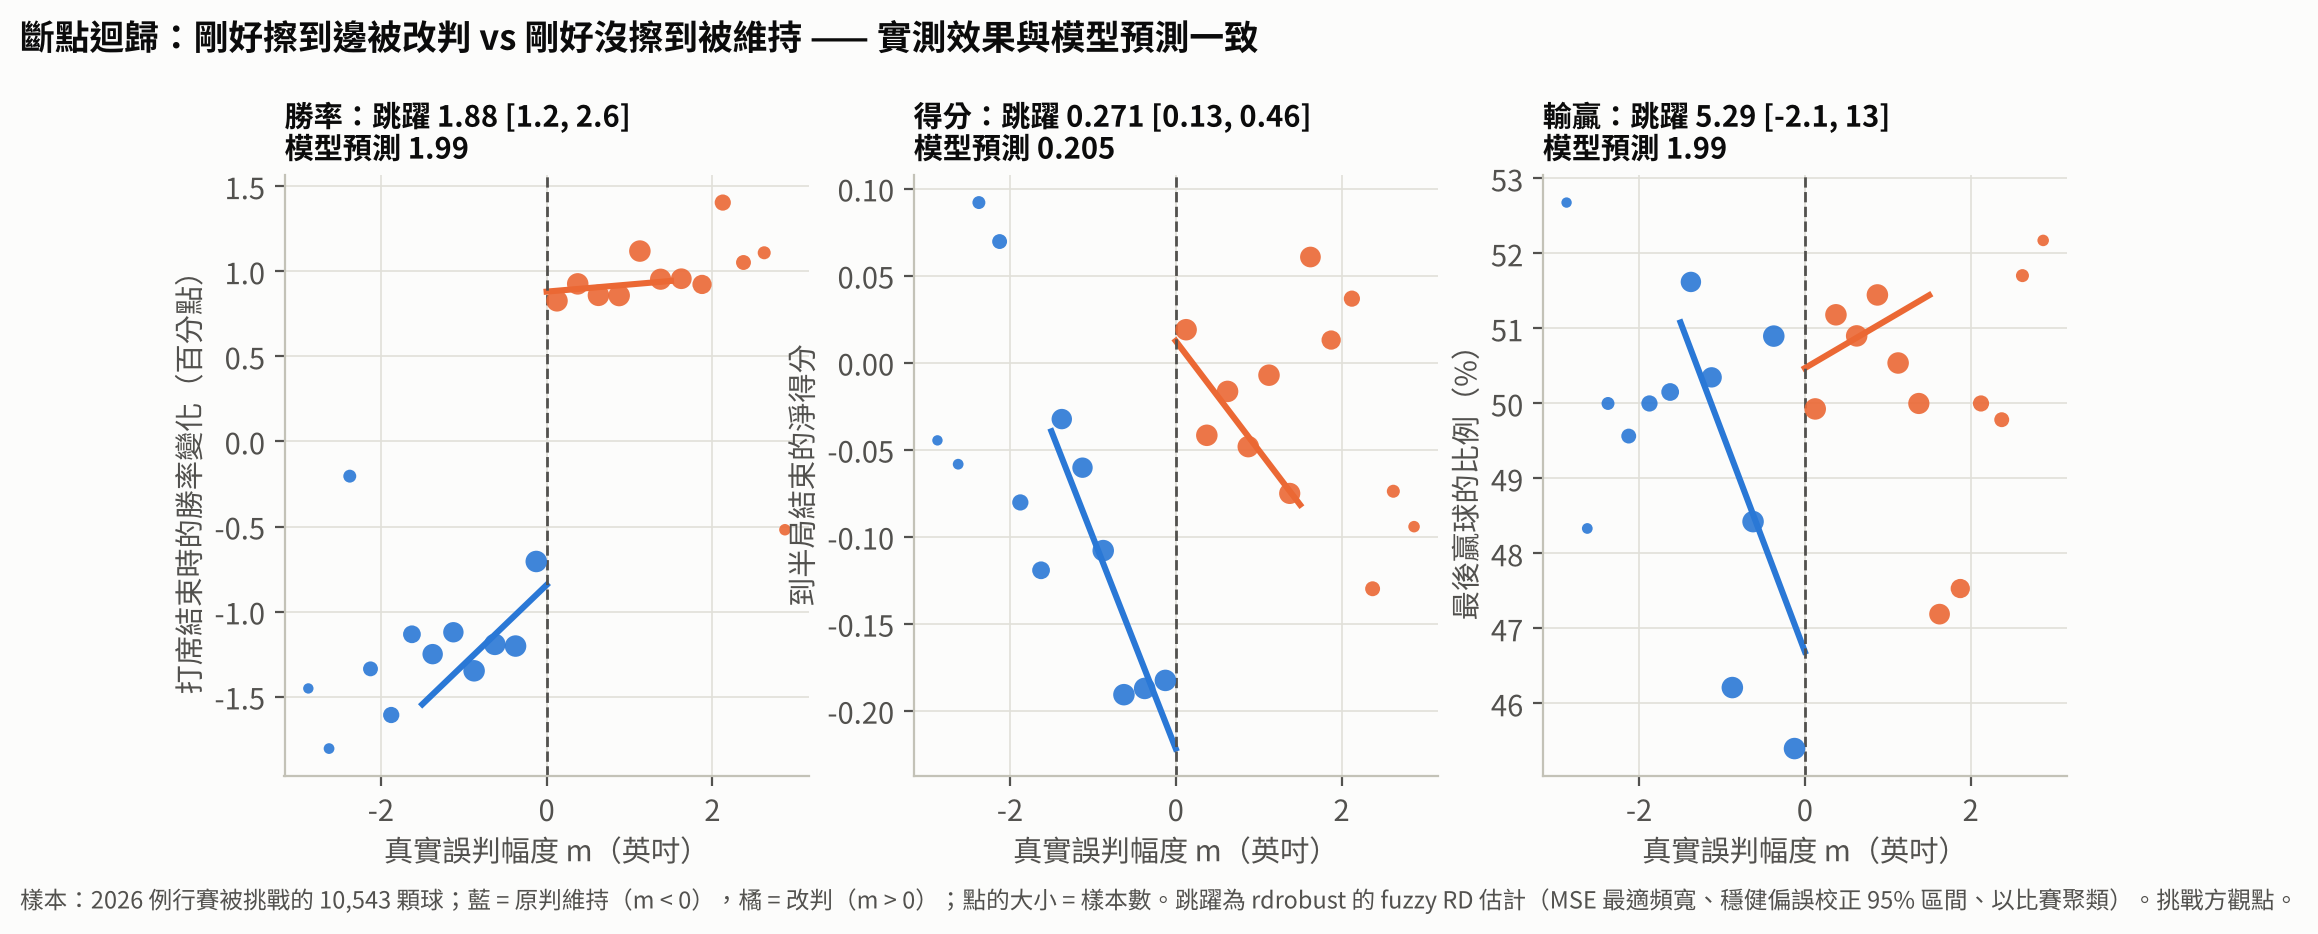

In [14]:
from src.rd import build_rd_sample, triangular_weights  # noqa: E402

rdm = T("rd_main")
main = rdm[(rdm.y == "Y_pa") & (rdm.spec.str.startswith("main"))].iloc[0]
h = main.h
check(17, "最適頻寬（英吋）", "0.95", h, "{:.2f}")
check(17, "頻寬內被挑戰的球", "4,930", main.n_eff, "{:,.0f}")
hs = rdm[(rdm.y == "Y_pa") & rdm.spec.str.startswith("h=")]
check(17, "換頻寬 0.75～3 的最小值", "1.79", hs.coef.min() * 100, "{:.2f}")
check(17, "換頻寬 0.75～3 的最大值", "1.88", hs.coef.max() * 100, "{:.2f}")

d = build_rd_sample()


def intercept(y: str, right: bool) -> float:
    s = d[(d.m > 0) if right else (d.m < 0)]
    s = s[s.m.abs() < h]
    sw = np.sqrt(triangular_weights(s.m, h).values)
    X = np.c_[np.ones(len(s)), s.m.values]
    return np.linalg.lstsq(X * sw[:, None], s[y].values * sw, rcond=None)[0][0]


yl, yr = intercept("Y_pa", False), intercept("Y_pa", True)
tl, tr = intercept("treat", False), intercept("treat", True)
check(18, "藍線在門檻（挑戰失敗）", "-0.817", yl * 100, "{:.3f}")
check(18, "橘線在門檻（改判）", "+0.968", yr * 100, "{:+.3f}")
check(18, "勝率的跳躍", "1.785", (yr - yl) * 100, "{:.3f}")
check(18, "改判率的跳躍", "0.947", tr - tl, "{:.3f}")
check(18, "改判效果 τ（rdrobust）", "1.88", main.coef * 100, "{:.2f}")
check(18, "95% 區間下界", "1.16", main.rb_lo * 100, "{:.2f}")
check(18, "95% 區間上界", "2.59", main.rb_hi * 100, "{:.2f}")
check(18, "模型預測（同樣加權）", "1.99", main.model_pred * 100, "{:.2f}")
runs = rdm[(rdm.y == "Y_runs") & (rdm.spec.str.startswith("main"))].iloc[0]
check(18, "改用得分：效果", "0.27", runs.coef, "{:.2f}")
check(18, "改用得分：模型預測", "0.21", runs.model_pred, "{:.2f}")
check(18, "得分 95% 區間", "0.13～0.46", f"{runs.rb_lo:.2f}～{runs.rb_hi:.2f}", "{}")
check(18, "密度檢定 p", "0.45", T("rd_checks").density_p[0], "{:.2f}")
check(18, "平衡檢定最小 p（簡報寫「全部大於 0.16」）", "0.16", T("rd_balance").rb_p.min(), "{:.2f}")
b = pd.cut(d.m, np.arange(-3, 3.01, 0.25))
check(18, "圖上 24 點的球數", "9,914", b.notna().sum(), "{:,}")
show_fig("abs_f9_rd.png")

## 第 19 頁｜模型二：球員判斷誤差

P(挑戰) ＝ λ × Φ((m − t) ÷ σ)。參數由 05 以最大概似法估計（`perc_params.csv`），σ 和 λ 以 log、logit 尺度估計。

In [15]:
pp = T("perc_params").set_index(["side", "param"]).est
sig = {(s, e): np.exp(pp[(s, f"log_sigma[{e}]")]) for s in ("def", "off") for e in ("bottom", "side", "top")}
lam = {s: 1 / (1 + np.exp(-pp[(s, "logit_lambda")])) for s in ("def", "off")}
print("σ（英吋）：", {k: round(v, 2) for k, v in sig.items()})
print("λ：", {k: round(v, 3) for k, v in lam.items()})
base = pd.DataFrame({k: [pp[("def", f"c[{ig}|{k}]")] for ig in ["1-3", "4-6", "7-8", "9", "10+"]]
                     for k in ("k2", "k1")}, index=["1-3", "4-6", "7-8", "9", "10+"]).T
print("捕手基本門檻 t（英吋）：\n", base.round(1).to_string())
check(19, "捕手左右邊 σ", "1.6", sig[("def", "side")], "{:.1f}")
check(19, "捕手 λ", "0.86", lam["def"], "{:.2f}")
check(19, "捕手 4–6 局剩 2 次的 t", "1.6", base.loc["k2", "4-6"], "{:.1f}")
for m_, s_ in [(0, "14%"), (2, "51%"), (4, "80%")]:
    check(19, f"m＝{m_} 英吋的挑戰機率（σ＝t＝1.6、λ＝0.86）", s_, 0.86 * norm.cdf((m_ - 1.6) / 1.6), PCT)
lik = lambda s: (1 - 0.86 * norm.cdf((0 - 1.6) / s)) * 0.86 * norm.cdf((2 - 1.6) / s) * 0.86 * norm.cdf((4 - 1.6) / s)  # noqa: E731
check(19, "三球的乘積（σ＝1.6）", "0.36", lik(1.6), "{:.2f}")
check(19, "三球的乘積（σ＝3）", "0.24", lik(3), "{:.2f}")

σ（英吋）： {('def', 'bottom'): np.float64(1.76), ('def', 'side'): np.float64(1.58), ('def', 'top'): np.float64(1.84), ('off', 'bottom'): np.float64(2.99), ('off', 'side'): np.float64(2.53), ('off', 'top'): np.float64(2.38)}
λ： {'def': np.float64(0.858), 'off': np.float64(0.971)}
捕手基本門檻 t（英吋）：
     1-3  4-6  7-8    9  10+
k2  2.1  1.6  1.2  0.3  0.8
k1  2.9  2.2  1.8  0.9  1.2
[第 19 頁] 捕手左右邊 σ：簡報 1.6｜重算 1.6 ✓
[第 19 頁] 捕手 λ：簡報 0.86｜重算 0.86 ✓
[第 19 頁] 捕手 4–6 局剩 2 次的 t：簡報 1.6｜重算 1.6 ✓
[第 19 頁] m＝0 英吋的挑戰機率（σ＝t＝1.6、λ＝0.86）：簡報 14%｜重算 14% ✓
[第 19 頁] m＝2 英吋的挑戰機率（σ＝t＝1.6、λ＝0.86）：簡報 51%｜重算 51% ✓
[第 19 頁] m＝4 英吋的挑戰機率（σ＝t＝1.6、λ＝0.86）：簡報 80%｜重算 80% ✓
[第 19 頁] 三球的乘積（σ＝1.6）：簡報 0.36｜重算 0.36 ✓
[第 19 頁] 三球的乘積（σ＝3）：簡報 0.24｜重算 0.24 ✓


## 第 20 頁｜判斷誤差的估計結果

[第 20 頁] 捕手 σ 最小：簡報 1.6｜重算 1.6 ✓
[第 20 頁] 捕手 σ 最大：簡報 1.8｜重算 1.8 ✓
[第 20 頁] 打者 σ 最小：簡報 2.4｜重算 2.4 ✓
[第 20 頁] 打者 σ 最大：簡報 3.0｜重算 3.0 ✓
[第 20 頁] 判對但只差 0.5 英吋內，捕手仍挑戰：簡報 14%｜重算 14% ✓
[第 20 頁] 判錯 1.5 英吋以上，打者 0 好球挑戰：簡報 21%｜重算 21% ✓
[第 20 頁] 判錯 1.5 英吋以上，打者兩好球挑戰：簡報 62%｜重算 62% ✓


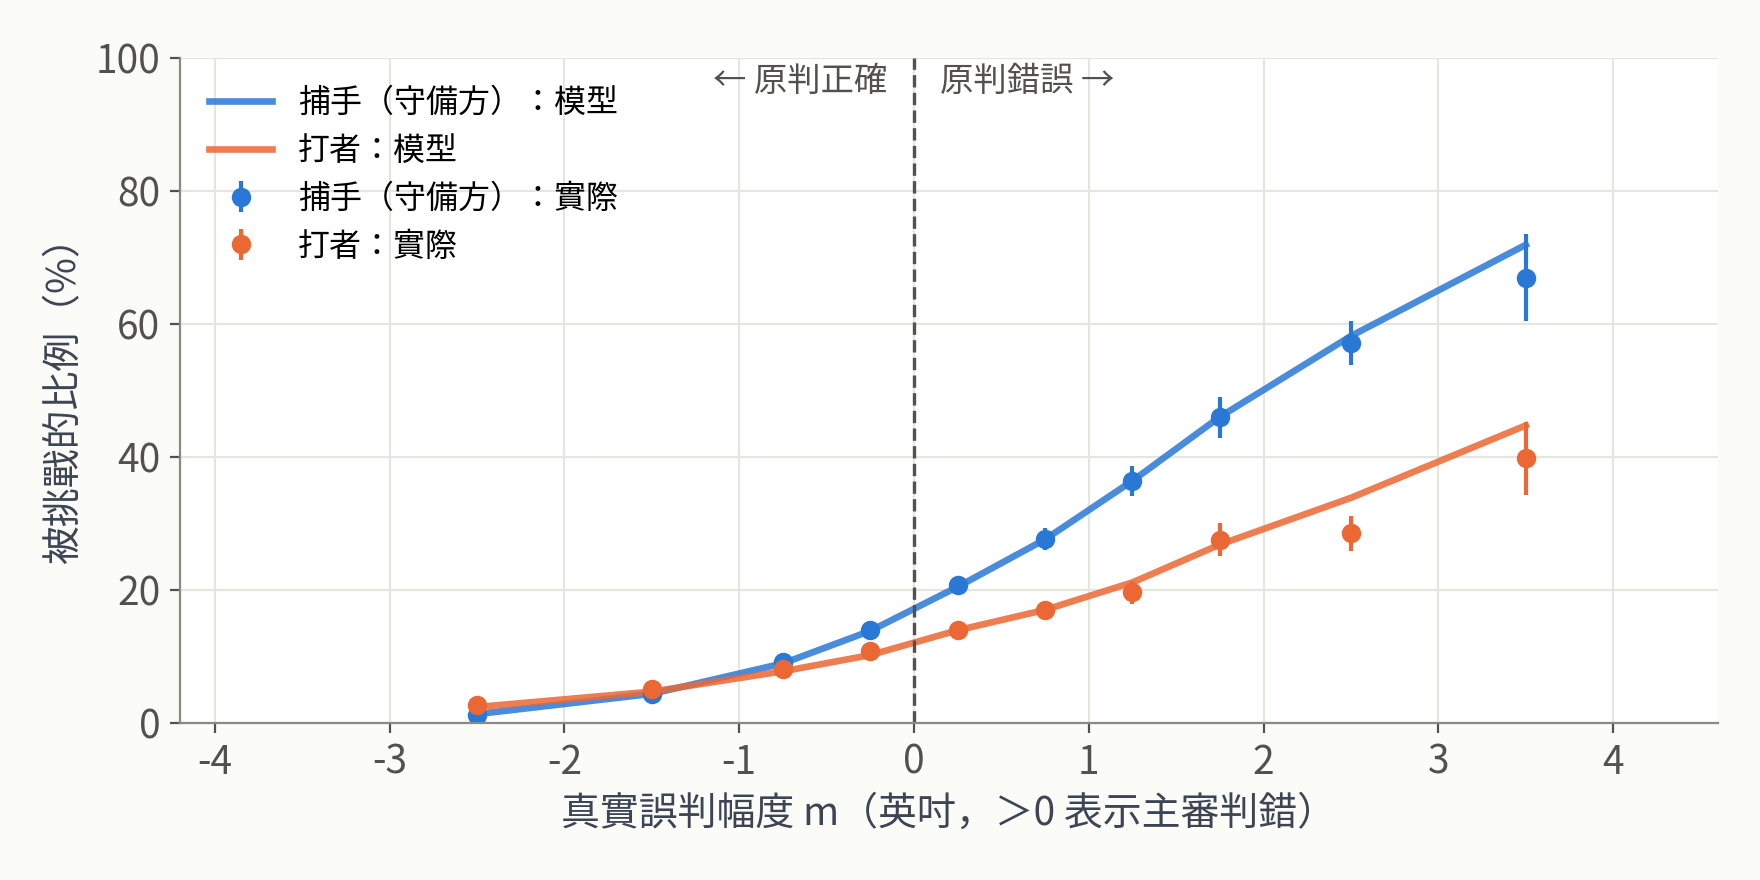

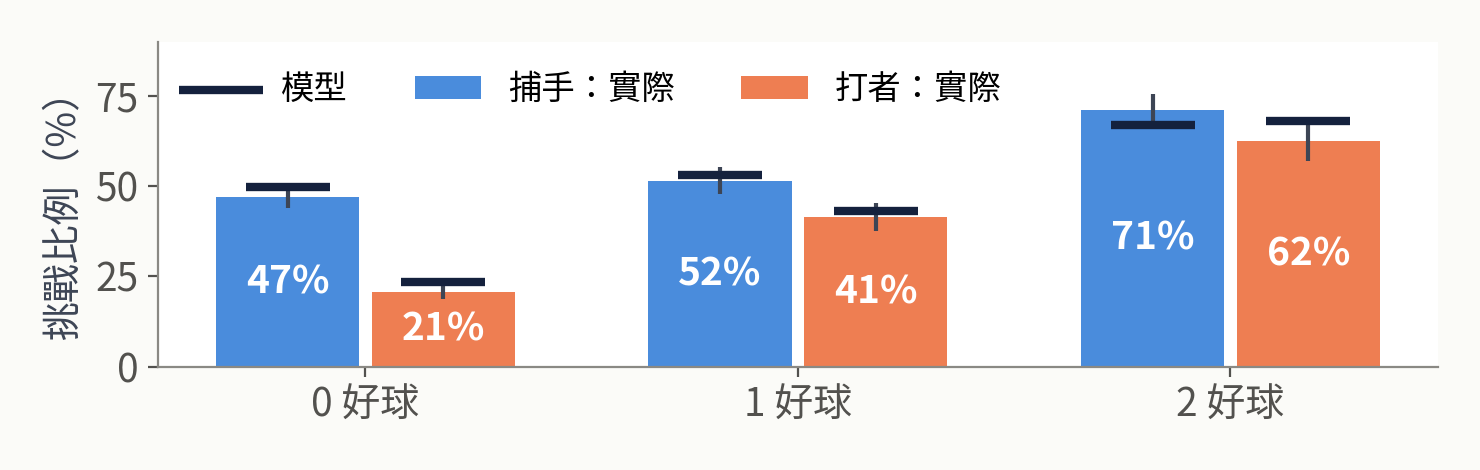

In [16]:
fb = T("perc_fit_bins")
check(20, "捕手 σ 最小", "1.6", min(sig[("def", e)] for e in ("bottom", "side", "top")), "{:.1f}")
check(20, "捕手 σ 最大", "1.8", max(sig[("def", e)] for e in ("bottom", "side", "top")), "{:.1f}")
check(20, "打者 σ 最小", "2.4", min(sig[("off", e)] for e in ("bottom", "side", "top")), "{:.1f}")
check(20, "打者 σ 最大", "3.0", max(sig[("off", e)] for e in ("bottom", "side", "top")), "{:.1f}")
r = fb[(fb.side == "def") & (fb.by == "mb") & (fb.group == "(-0.5, 0.0]")].iloc[0]
check(20, "判對但只差 0.5 英吋內，捕手仍挑戰", "14%", r.actual, PCT)
mc = fb[(fb.side == "off") & (fb.by == "mb_cnt")].set_index("group")
check(20, "判錯 1.5 英吋以上，打者 0 好球挑戰", "21%", mc.loc["m>1.5|0s", "actual"], PCT)
check(20, "判錯 1.5 英吋以上，打者兩好球挑戰", "62%", mc.loc["m>1.5|2s", "actual"], PCT)
show_fig("slide_p20_perception.png")
show_fig("slide_p20_by_count.png")

## 第 21 頁｜模型三：失敗代價 C（只剩 1 次）

[第 21 頁] 第 1 局 C（只剩 1 次）：簡報 1.65｜重算 1.65 ✓
[第 21 頁] 第 9 局 C（只剩 1 次）：簡報 0.30｜重算 0.30 ✓
[第 21 頁] 第 9 局 Savant 換算：簡報 1.15｜重算 1.15 ✓
[第 21 頁] Savant 高估倍數：簡報 4｜重算 4 ✓
[第 21 頁] 第 9 局 ÷ 第 1 局（結論頁：五分之一）：簡報 0.2｜重算 0.2 ✓
[第 21 頁] 決策序列（隊×場）：簡報 4,858｜重算 4,858 ✓
[第 21 頁] C 收斂的輪數：簡報 9｜重算 9 ✓


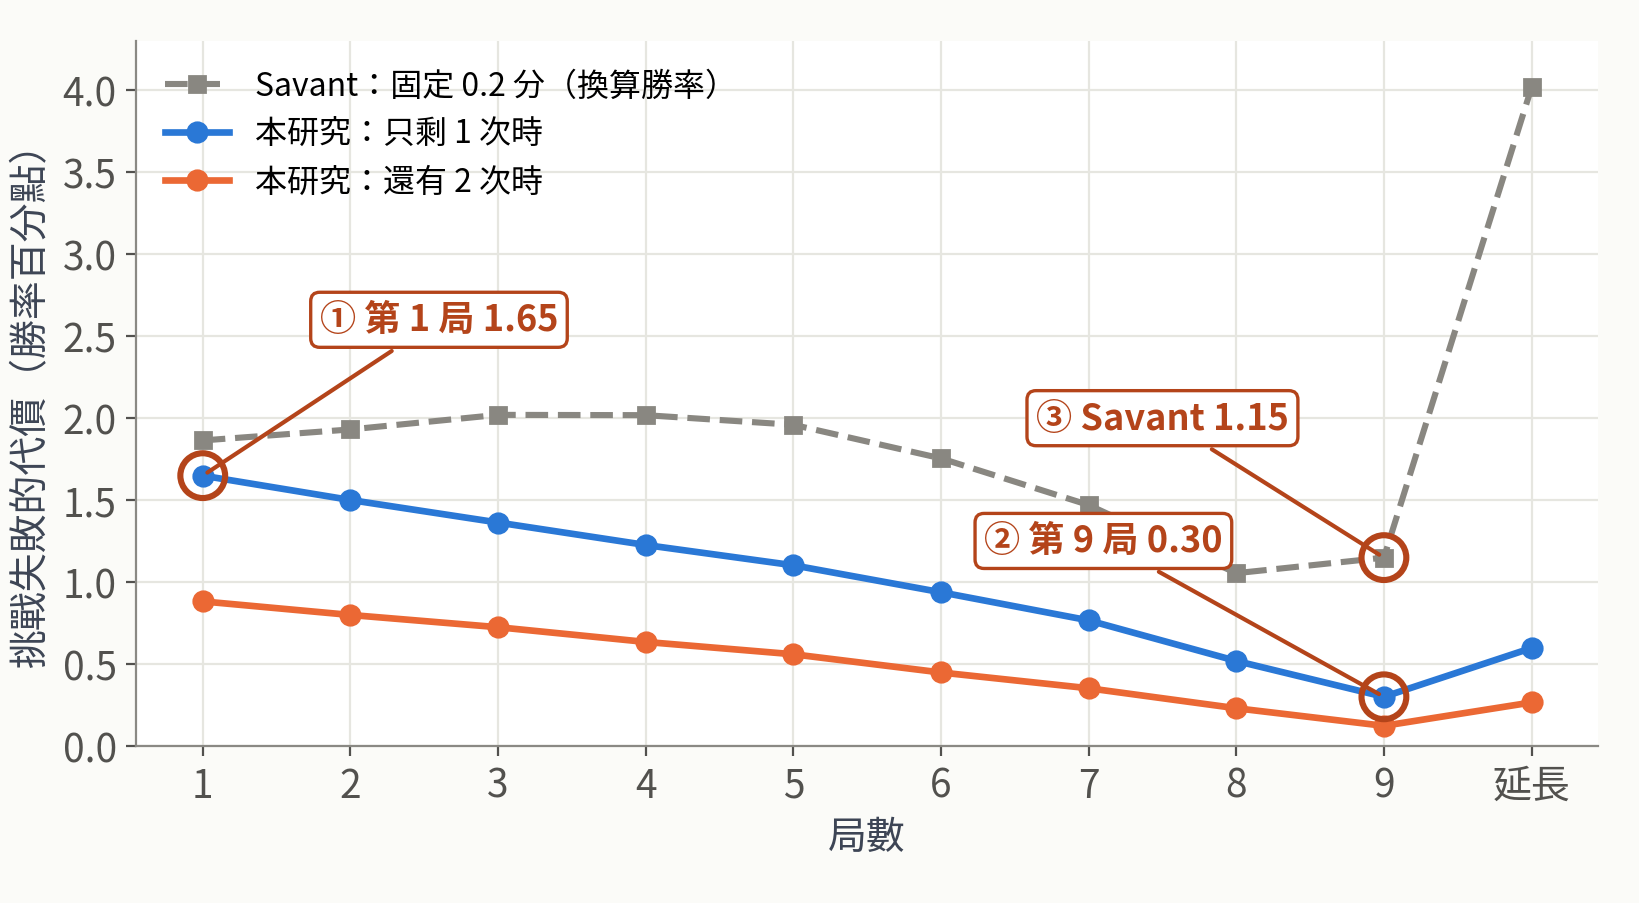

In [17]:
f3 = T("f3_slide_data").set_index("inn")
check(21, "第 1 局 C（只剩 1 次）", "1.65", f3.loc[1, "C1"], "{:.2f}")
check(21, "第 9 局 C（只剩 1 次）", "0.30", f3.loc[9, "C1"], "{:.2f}")
check(21, "第 9 局 Savant 換算", "1.15", f3.loc[9, "sav"], "{:.2f}")
check(21, "Savant 高估倍數", "4", f3.loc[9, "sav"] / f3.loc[9, "C1"], "{:.0f}")
check(21, "第 9 局 ÷ 第 1 局（結論頁：五分之一）", "0.2", f3.loc[9, "C1"] / f3.loc[1, "C1"], "{:.1f}")
check(21, "決策序列（隊×場）", "4,858", len(pd.read_parquet(POLICY_VALUES)), "{:,}")
check(21, "C 收斂的輪數", "9", len(load_pickle(ROOT / "data/processed/dp_hist.pkl")["hist"]["opt"]), "{}")
show_fig("slide_p21_cost.png")

## 第 22 頁｜結果一：挑戰門檻卡

p* ＝ C ÷ (G ＋ C)，每格是該情境所有決策點的 p* 中位數（`card_pstar.csv`，07 card）。

In [18]:
cp = T("card_pstar")
print(cp[cp.score == "all"].set_index(["k", "cgrp"])[["1-3", "4-6", "7-8", "9", "10+"]].round(2).to_string())
exs = T("slide_examples").set_index("例子")
e1, e2 = exs.iloc[0], exs.iloc[1]
check(22, "例：5 局下平手 1-1 的 G", "1.41", e1.G * 100, "{:.2f}")
check(22, "例：還有 2 次的 C", "0.74", e1.C2 * 100, "{:.2f}")
check(22, "例：還有 2 次的 p*", "34%", e1["p*_C2"], PCT)
check(22, "例：只剩 1 次的 C", "1.41", e1.C1 * 100, "{:.2f}")
check(22, "例：只剩 1 次的 p*", "50%", e1["p*_C1"], PCT)
check(22, "第 9 局 3-2 的 G", "3.67", e2.G * 100, "{:.2f}")
check(22, "第 9 局 3-2 的 C（還有 2 次）", "0.10", e2.C2 * 100, "{:.2f}")
check(22, "第 9 局 3-2 的 p*", "3%", e2["p*_C2"], PCT)

                      1-3   4-6   7-8     9   10+
k cgrp                                           
2 a 0-0/1-0/0-1/1-1  0.53  0.45  0.34  0.15  0.10
  b 2-0/2-1/3-0/3-1  0.34  0.27  0.20  0.07  0.06
  c 0-2/1-2          0.33  0.26  0.18  0.07  0.04
  d 2-2              0.24  0.19  0.12  0.04  0.03
  e 3-2              0.14  0.11  0.08  0.02  0.02
1 a 0-0/1-0/0-1/1-1  0.68  0.61  0.54  0.31  0.19
  b 2-0/2-1/3-0/3-1  0.49  0.43  0.35  0.15  0.13
  c 0-2/1-2          0.48  0.41  0.33  0.16  0.08
  d 2-2              0.37  0.31  0.24  0.10  0.06
  e 3-2              0.23  0.19  0.15  0.05  0.04
[第 22 頁] 例：5 局下平手 1-1 的 G：簡報 1.41｜重算 1.41 ✓
[第 22 頁] 例：還有 2 次的 C：簡報 0.74｜重算 0.74 ✓
[第 22 頁] 例：還有 2 次的 p*：簡報 34%｜重算 34% ✓
[第 22 頁] 例：只剩 1 次的 C：簡報 1.41｜重算 1.41 ✓
[第 22 頁] 例：只剩 1 次的 p*：簡報 50%｜重算 50% ✓
[第 22 頁] 第 9 局 3-2 的 G：簡報 3.67｜重算 3.67 ✓
[第 22 頁] 第 9 局 3-2 的 C（還有 2 次）：簡報 0.10｜重算 0.10 ✓
[第 22 頁] 第 9 局 3-2 的 p*：簡報 3%｜重算 3% ✓


## 第 23 頁｜壘況、出局數與比分（還有 2 次）

ig           1-3   10+   4-6   7-8     9
bg    cg                                
一壘有人  2-2   0.22  0.04  0.16  0.10  0.03
      3-2   0.13  0.04  0.09  0.05  0.01
      一般    0.48  0.15  0.40  0.30  0.13
      兩好球   0.29  0.08  0.23  0.15  0.06
      打者有利  0.31  0.08  0.24  0.17  0.06
壘上無人  2-2   0.27  0.12  0.22  0.16  0.07
      3-2   0.16  0.04  0.13  0.09  0.03
      一般    0.56  0.34  0.49  0.39  0.19
      兩好球   0.38  0.19  0.31  0.23  0.11
      打者有利  0.35  0.20  0.29  0.22  0.09
得點圈有人 2-2   0.17  0.03  0.13  0.09  0.03
      3-2   0.11  0.02  0.09  0.06  0.02
      一般    0.44  0.10  0.37  0.28  0.12
      兩好球   0.21  0.04  0.17  0.11  0.04
      打者有利  0.33  0.06  0.26  0.20  0.05
滿壘    2-2   0.09  0.02  0.07  0.06  0.02
      3-2   0.05  0.01  0.04  0.03  0.00
      一般    0.29  0.06  0.23  0.17  0.08
      兩好球   0.14  0.02  0.11  0.08  0.03
      打者有利  0.15  0.02  0.12  0.09  0.03
[第 23 頁] 滿壘、一般球數、1–3 局：簡報 29%｜重算 29% ✓
[第 23 頁] 無人、一般球數、7–8 局：簡報 39%｜重算 39% ✓
[第 23 頁] 0 出局：簡報 48%

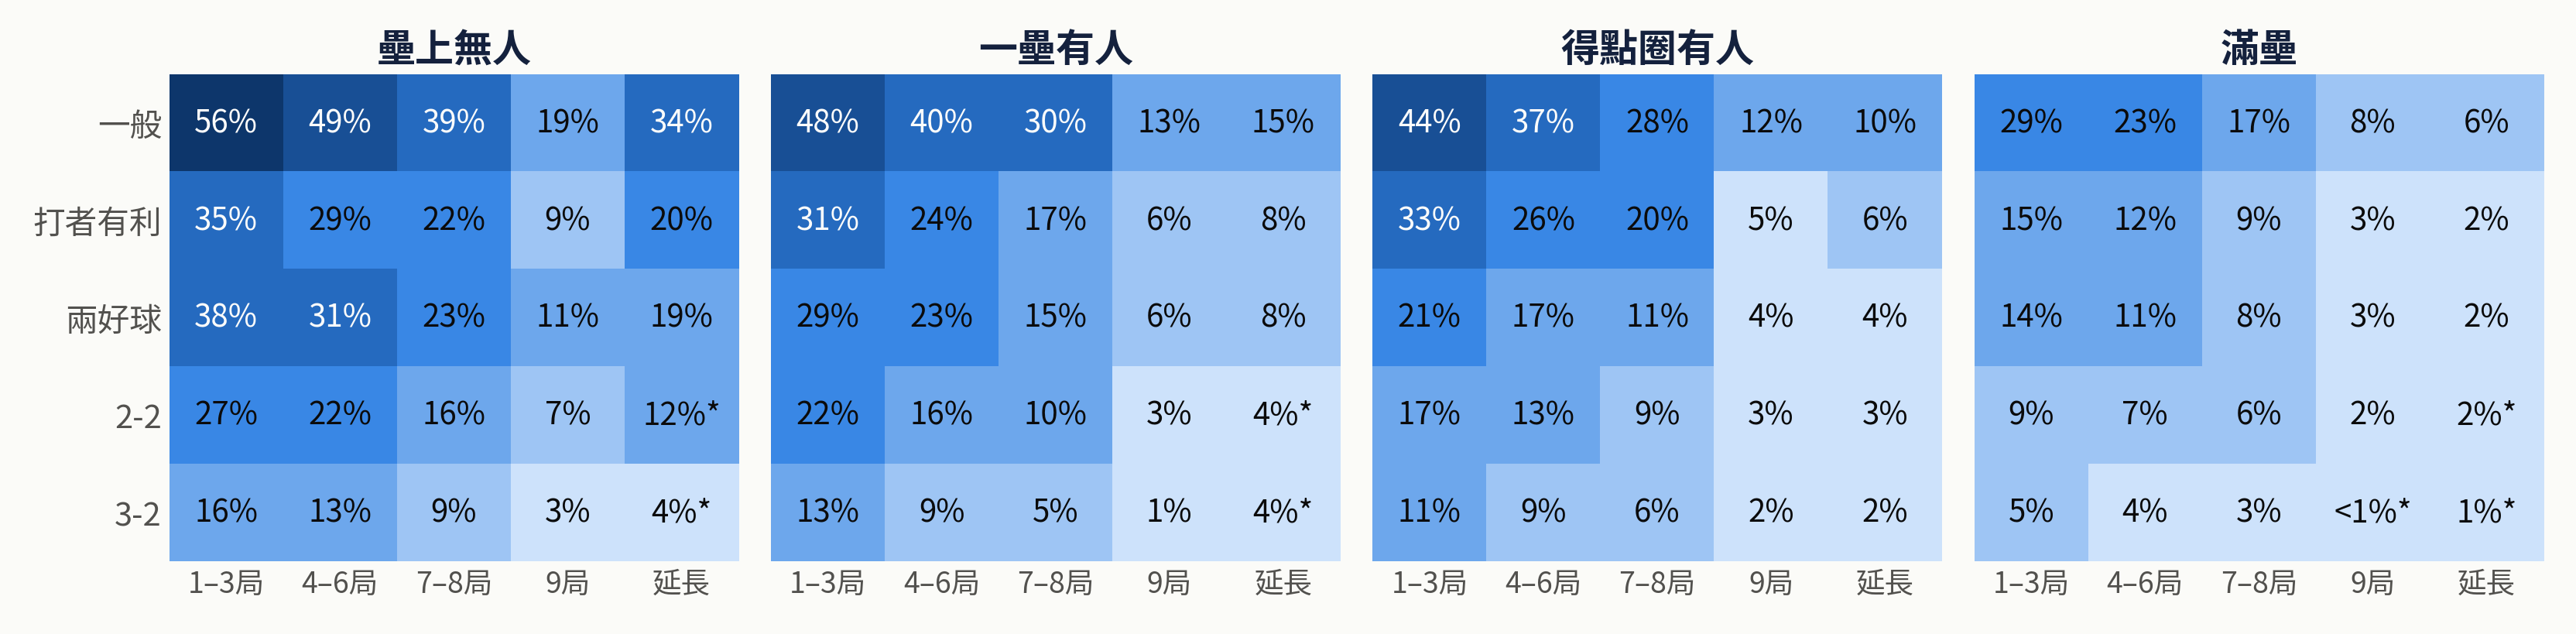

In [19]:
bb = T("card_pstar_by_bases")
print(bb.pivot_table(index=["bg", "cg"], columns="ig", values="median").round(2).to_string())
pick = lambda bg, cg, ig: bb[(bb.bg == bg) & (bb.cg == cg) & (bb.ig == ig)]["median"].iloc[0]  # noqa: E731
check(23, "滿壘、一般球數、1–3 局", "29%", pick("滿壘", "一般", "1-3"), PCT)
check(23, "無人、一般球數、7–8 局", "39%", pick("壘上無人", "一般", "7-8"), PCT)
ctx = T("r1_context_tables")
o = ctx[ctx.表.str.startswith("出局")].set_index("列")["p*"]
check(23, "0 出局", "48%", o["0 出局"], PCT)
check(23, "1 出局", "53%", o["1 出局"], PCT)
check(23, "2 出局", "59%", o["2 出局"], PCT)
sc_ = ctx[ctx.表.str.startswith("比分")].pivot(index="列", columns="欄", values="p*")[["1-3", "4-6", "7-8", "9", "10+"]]
print(sc_.round(2).to_string())
check(23, "差 1 分內，1–3 局", "53%", sc_.loc["差 1 分以內", "1-3"], PCT)
check(23, "差 4 分以上，1–3 局", "51%", sc_.loc["差 4 分以上", "1-3"], PCT)
check(23, "差 1 分內，第 9 局", "12%", sc_.loc["差 1 分以內", "9"], PCT)
check(23, "差 4 分以上，第 9 局", "30%", sc_.loc["差 4 分以上", "9"], PCT)
show_fig("slide_p23_by_bases.png")

## 第 24 頁｜結果二：實際門檻 vs 最佳門檻

實際門檻 τ：把球員的 t 英吋用貝氏定理換成「看起來差 t 英吋的球裡，真的判錯的比例」（07 h2）。

In [20]:
hc = T("h2_coarse")
print(hc[["side", "ig", "k", "pstar", "tau"]].round(2).to_string(index=False))
r9 = hc[(hc.side == "off") & (hc.ig == "9") & (hc.k == 2)].iloc[0]
check(24, "打者第 9 局還有 2 次：實際（簡報寫「約 40%」）", "40%", r9.tau, PCT)
check(24, "打者第 9 局還有 2 次：最佳", "15%", r9.pstar, PCT)
cells = T("h2_cells")
r9a = cells[(cells.side == "off") & (cells.ig == "9") & (cells.k == 2) & cells.cgrp.str.startswith("a")].iloc[0]
check(24, "例：第 9 局一般球數打者，實際", "42%", r9a.tau, PCT)
check(24, "例：第 9 局一般球數打者，最佳", "17%", r9a.pstar, PCT)
k2 = hc[hc.k == 2]
print("還有 2 次時，實際門檻高於最佳的格數：", int((k2.tau > k2.pstar).sum()), "/", len(k2))
k1 = hc[hc.k == 1]
print("只剩 1 次、實際低於最佳（太積極）的格：")
print(k1[k1.tau < k1.pstar][["side", "ig", "pstar", "tau"]].round(3).to_string(index=False))

side  ig  k  pstar  tau
 def 1-3  1   0.61 0.64
 def 1-3  2   0.47 0.53
 def 10+  1   0.17 0.34
 def 10+  2   0.09 0.30
 def 4-6  1   0.55 0.54
 def 4-6  2   0.39 0.44
 def 7-8  1   0.47 0.48
 def 7-8  2   0.28 0.39
 def   9  1   0.24 0.33
 def   9  2   0.13 0.25
 off 1-3  1   0.63 0.58
 off 1-3  2   0.50 0.56
 off 10+  1   0.19 0.38
 off 10+  2   0.09 0.33
 off 4-6  1   0.56 0.56
 off 4-6  2   0.42 0.51
 off 7-8  1   0.47 0.50
 off 7-8  2   0.30 0.47
 off   9  1   0.27 0.42
 off   9  2   0.15 0.39
[第 24 頁] 打者第 9 局還有 2 次：實際（簡報寫「約 40%」）：簡報 40%｜重算 39% ≈
[第 24 頁] 打者第 9 局還有 2 次：最佳：簡報 15%｜重算 15% ✓
[第 24 頁] 例：第 9 局一般球數打者，實際：簡報 42%｜重算 42% ✓
[第 24 頁] 例：第 9 局一般球數打者，最佳：簡報 17%｜重算 17% ✓
還有 2 次時，實際門檻高於最佳的格數： 10 / 10
只剩 1 次、實際低於最佳（太積極）的格：
side  ig  pstar   tau
 def 4-6  0.548 0.542
 off 1-3  0.629 0.579
 off 4-6  0.564 0.559


## 第 25 頁｜結果三：每隊每季的勝場（以比賽為單位重抽 200 次）

[第 25 頁] 實際：勝場：簡報 3.42｜重算 3.42 ✓
      95% 區間 3.28～3.59
[第 25 頁] Savant 公式：勝場：簡報 2.88｜重算 2.88 ✓
      95% 區間 2.74～2.99
[第 25 頁] 固定門檻：勝場：簡報 4.23｜重算 4.23 ✓
      95% 區間 4.08～4.37
[第 25 頁] 最佳：勝場：簡報 4.47｜重算 4.47 ✓
      95% 區間 4.32～4.61
[第 25 頁] 完美判斷：勝場：簡報 10.49｜重算 10.49 ✓
      95% 區間 10.22～10.76
[第 25 頁] 最佳 − 實際：簡報 1.05｜重算 1.05 ✓
[第 25 頁] 95% 區間下界：簡報 0.94｜重算 0.94 ✓
[第 25 頁] 95% 區間上界：簡報 1.17｜重算 1.17 ✓
[第 25 頁] 固定門檻 − 實際（表上的 4.23 − 3.42）：簡報 0.81｜重算 0.81 ✓
[第 25 頁] 最佳 − 固定門檻（表上的 4.47 − 4.23）：簡報 0.24｜重算 0.24 ✓
[第 25 頁] Savant − 實際：簡報 -0.54｜重算 -0.54 ✓
[第 25 頁] 完美判斷 − 最佳：簡報 6.0｜重算 6.0 ✓
[第 25 頁] 會漏看時（λ）最佳 − 實際：簡報 0.79｜重算 0.79 ✓
[第 25 頁] 1.05 勝換算（萬美元，簡報寫「約 1,180」）：簡報 1,180｜重算 1,183 ≈


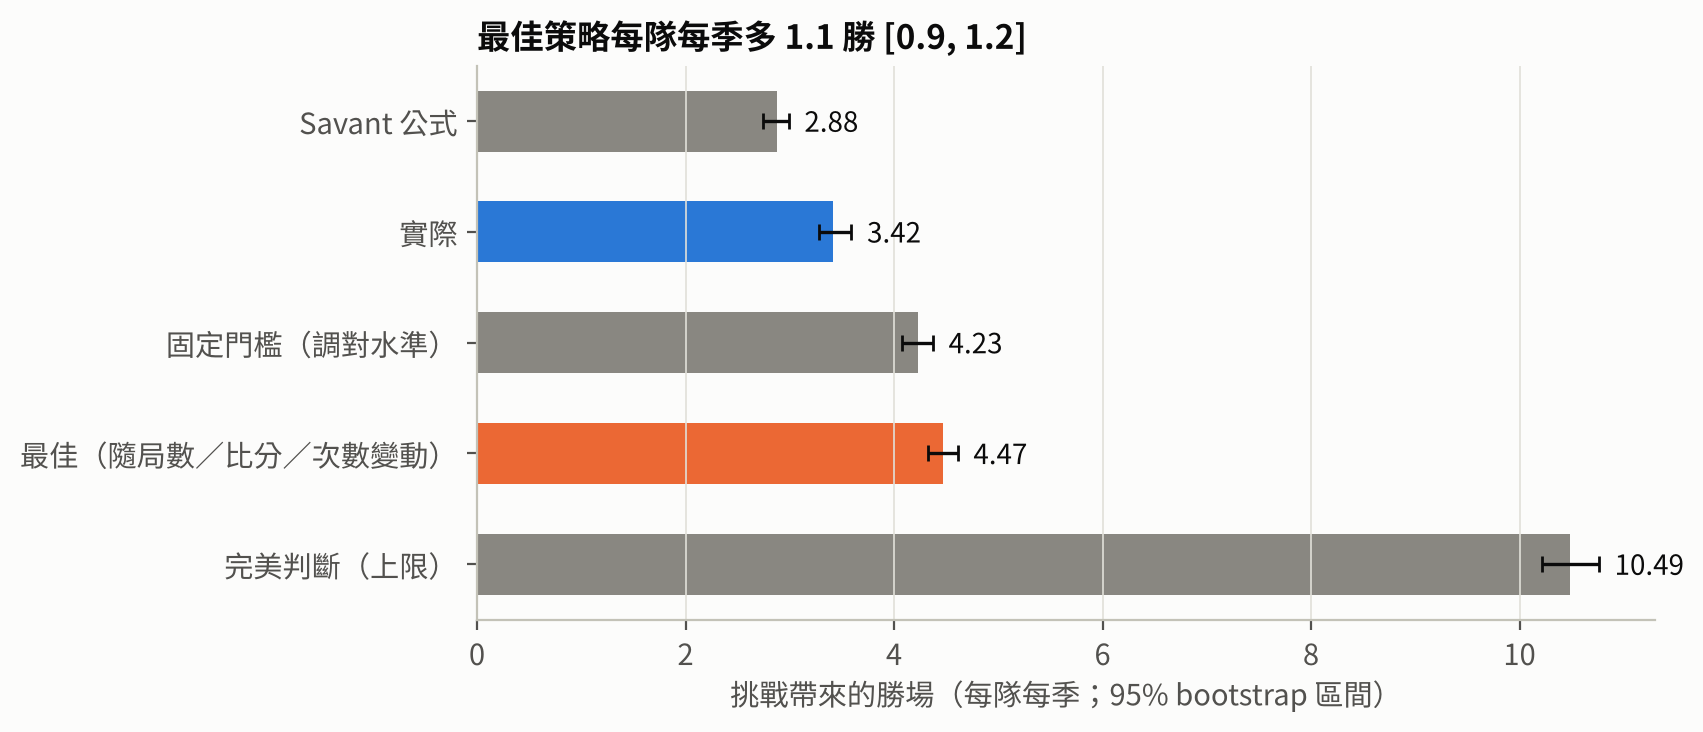

In [21]:
bs = T("h3_bootstrap_summary").set_index("Unnamed: 0")
for k, lab, s in [("actual", "實際", "3.42"), ("savant", "Savant 公式", "2.88"), ("static", "固定門檻", "4.23"),
                  ("opt", "最佳", "4.47"), ("perfect", "完美判斷", "10.49")]:
    check(25, f"{lab}：勝場", s, bs.loc[k, "mean"], "{:.2f}")
    print(f"      95% 區間 {bs.loc[k, 'lo']:.2f}～{bs.loc[k, 'hi']:.2f}")
check(25, "最佳 − 實際", "1.05", bs.loc["opt-actual", "mean"], "{:.2f}")
check(25, "95% 區間下界", "0.94", bs.loc["opt-actual", "lo"], "{:.2f}")
check(25, "95% 區間上界", "1.17", bs.loc["opt-actual", "hi"], "{:.2f}")
check(25, "固定門檻 − 實際（表上的 4.23 − 3.42）", "0.81", round(bs.loc["static", "mean"], 2) - round(bs.loc["actual", "mean"], 2), "{:.2f}")
check(25, "最佳 − 固定門檻（表上的 4.47 − 4.23）", "0.24", round(bs.loc["opt", "mean"], 2) - round(bs.loc["static", "mean"], 2), "{:.2f}")
check(25, "Savant − 實際", "-0.54", bs.loc["savant-actual", "mean"], "{:.2f}")
check(25, "完美判斷 − 最佳", "6.0", bs.loc["perfect-opt", "mean"], "{:.1f}")
check(25, "會漏看時（λ）最佳 − 實際", "0.79", bs.loc["opt_lam", "mean"] - bs.loc["actual", "mean"], "{:.2f}")
WAR_USD = 11.23  # 百萬美元／勝，FanGraphs 2026
check(25, "1.05 勝換算（萬美元，簡報寫「約 1,180」）", "1,180", bs.loc["opt-actual", "mean"] * WAR_USD * 100, "{:,.0f}")
show_fig("abs_f7_policies.png")

## 第 26 頁｜各隊差異（各隊 162 場重抽 2,000 次）

team  actual  opt  gap_opt_actual  gap_lo  gap_hi
 MIA    4.22 4.55            0.33   -0.22    0.88
 MIN    4.44 4.85            0.41   -0.10    1.00
 NYY    3.40 3.83            0.44   -0.03    0.91
 COL    3.85 4.33            0.47   -0.13    1.11
 CWS    4.22 4.71            0.49   -0.35    1.19
 CIN    4.61 5.28            0.67   -0.02    1.42
 CHC    3.29 3.98            0.69    0.14    1.34
 ATH    4.26 4.97            0.71    0.11    1.28
 HOU    3.04 3.85            0.81    0.28    1.37
  KC    2.99 3.81            0.82    0.28    1.35
 DET    2.99 3.88            0.88    0.36    1.43
 LAA    4.11 5.03            0.93    0.25    1.58
 TOR    3.12 4.08            0.97    0.37    1.61
  AZ    3.31 4.35            1.04    0.41    1.67
 BAL    3.38 4.44            1.06    0.34    1.64
 PHI    3.01 4.11            1.09    0.48    1.74
  SF    2.75 3.89            1.15    0.57    1.74
 TEX    3.37 4.54            1.17    0.50    1.91
 BOS    3.58 4.84            1.26    0.51    1.95


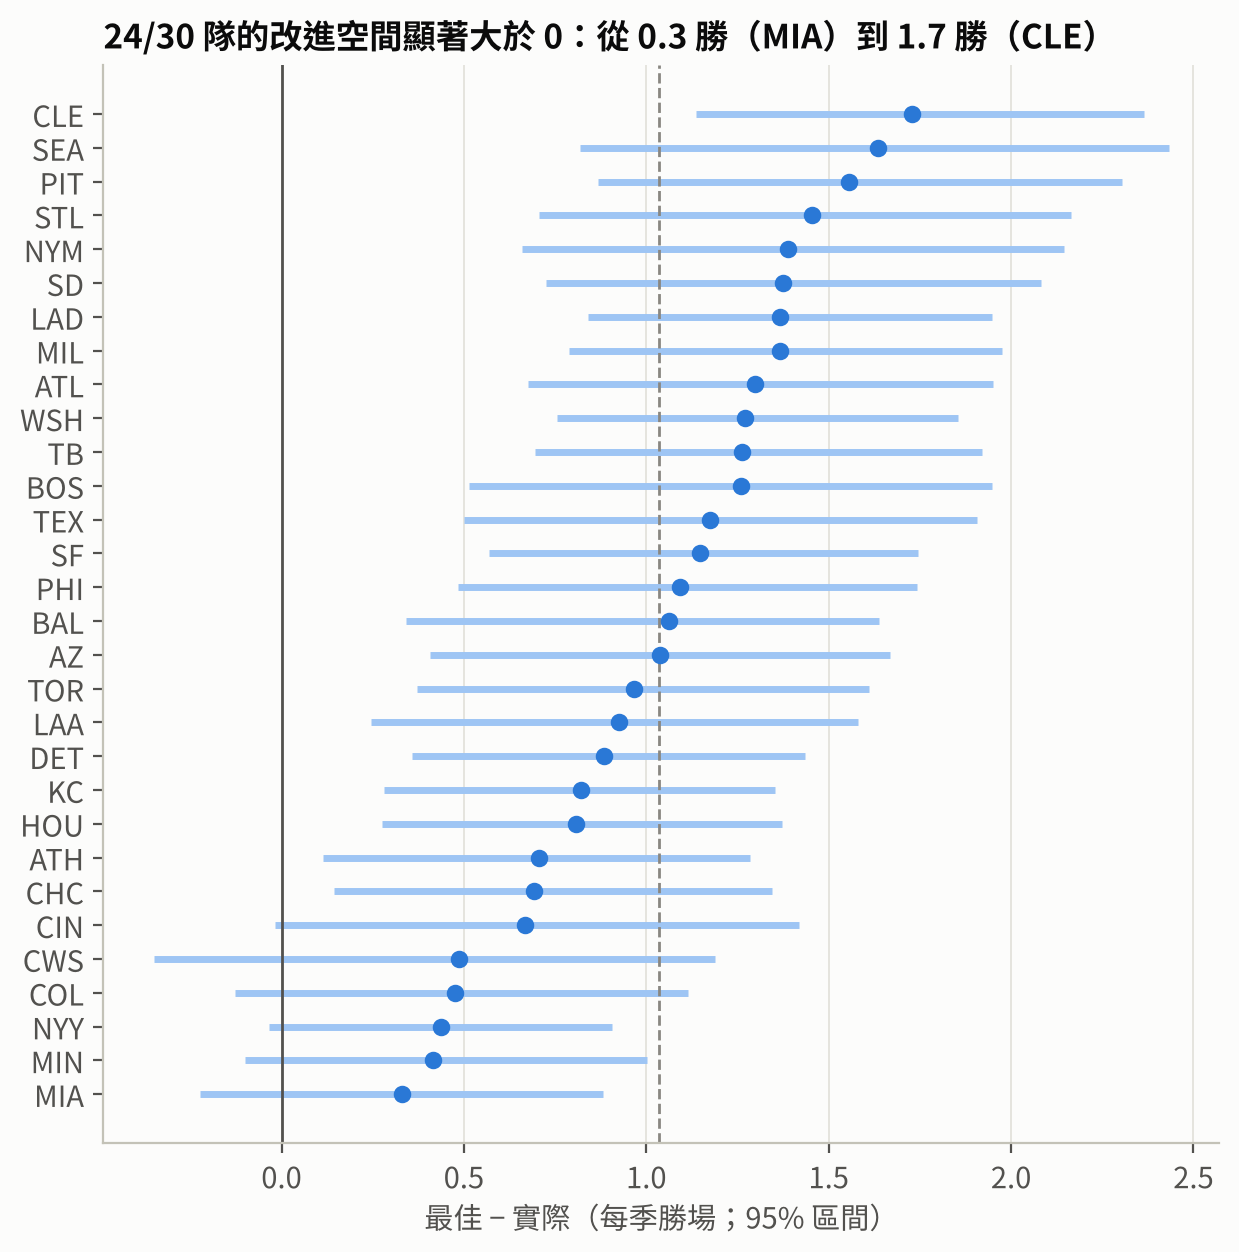

In [22]:
tm = T("h3_teams").sort_values("gap_opt_actual")
print(tm[["team", "actual", "opt", "gap_opt_actual", "gap_lo", "gap_hi"]].round(2).to_string(index=False))
check(26, "最多（CLE）", "1.7", tm.set_index("team").loc["CLE", "gap_opt_actual"], "{:.1f}")
check(26, "最少（MIA）", "0.3", tm.set_index("team").loc["MIA", "gap_opt_actual"], "{:.1f}")
check(26, "區間在 0 右邊的隊數", "24", (tm.gap_lo > 0).sum(), "{}")
check(26, "各隊差距的標準差", "0.39", tm.gap_opt_actual.std(), "{:.2f}")
show_fig("abs_f8_teams.png")

## 第 27 頁｜統整：所有情境一起看

把全季決策點的最佳門檻（logit p*）放進一條迴歸，用 7 個因素解釋，再一次拿掉一個看 R² 掉多少（13）。

       因素  R2下降  全模型R2
       球數 0.157  0.492
       局數 0.132  0.492
   剩餘挑戰次數 0.081  0.492
     壘上跑者 0.076  0.492
       比分 0.051  0.492
      出局數 0.042  0.492
攻守（捕手／打者） 0.000  0.492
[第 27 頁] 七個因素一起的 R²（約一半）：簡報 0.49｜重算 0.49 ✓
[第 27 頁] 球數／一般：簡報 45%｜重算 45% ✓
[第 27 頁] 球數／3-2：簡報 12%｜重算 12% ✓
[第 27 頁] 局數／1-3：簡報 46%｜重算 46% ✓
[第 27 頁] 局數／9：簡報 12%｜重算 12% ✓
[第 27 頁] 剩餘次數／還有 2 次：簡報 37%｜重算 37% ✓
[第 27 頁] 剩餘次數／只剩 1 次：簡報 54%｜重算 54% ✓
[第 27 頁] 壘況／滿壘：簡報 17%｜重算 17% ✓
[第 27 頁] 壘況／壘上無人：簡報 43%｜重算 43% ✓
[第 27 頁] 比分（9 局）／差 1 分以內：簡報 10%｜重算 10% ✓
[第 27 頁] 比分（9 局）／差 4 分以上：簡報 23%｜重算 23% ✓
前 3 局比分接近／大比分差： 0.47 0.45


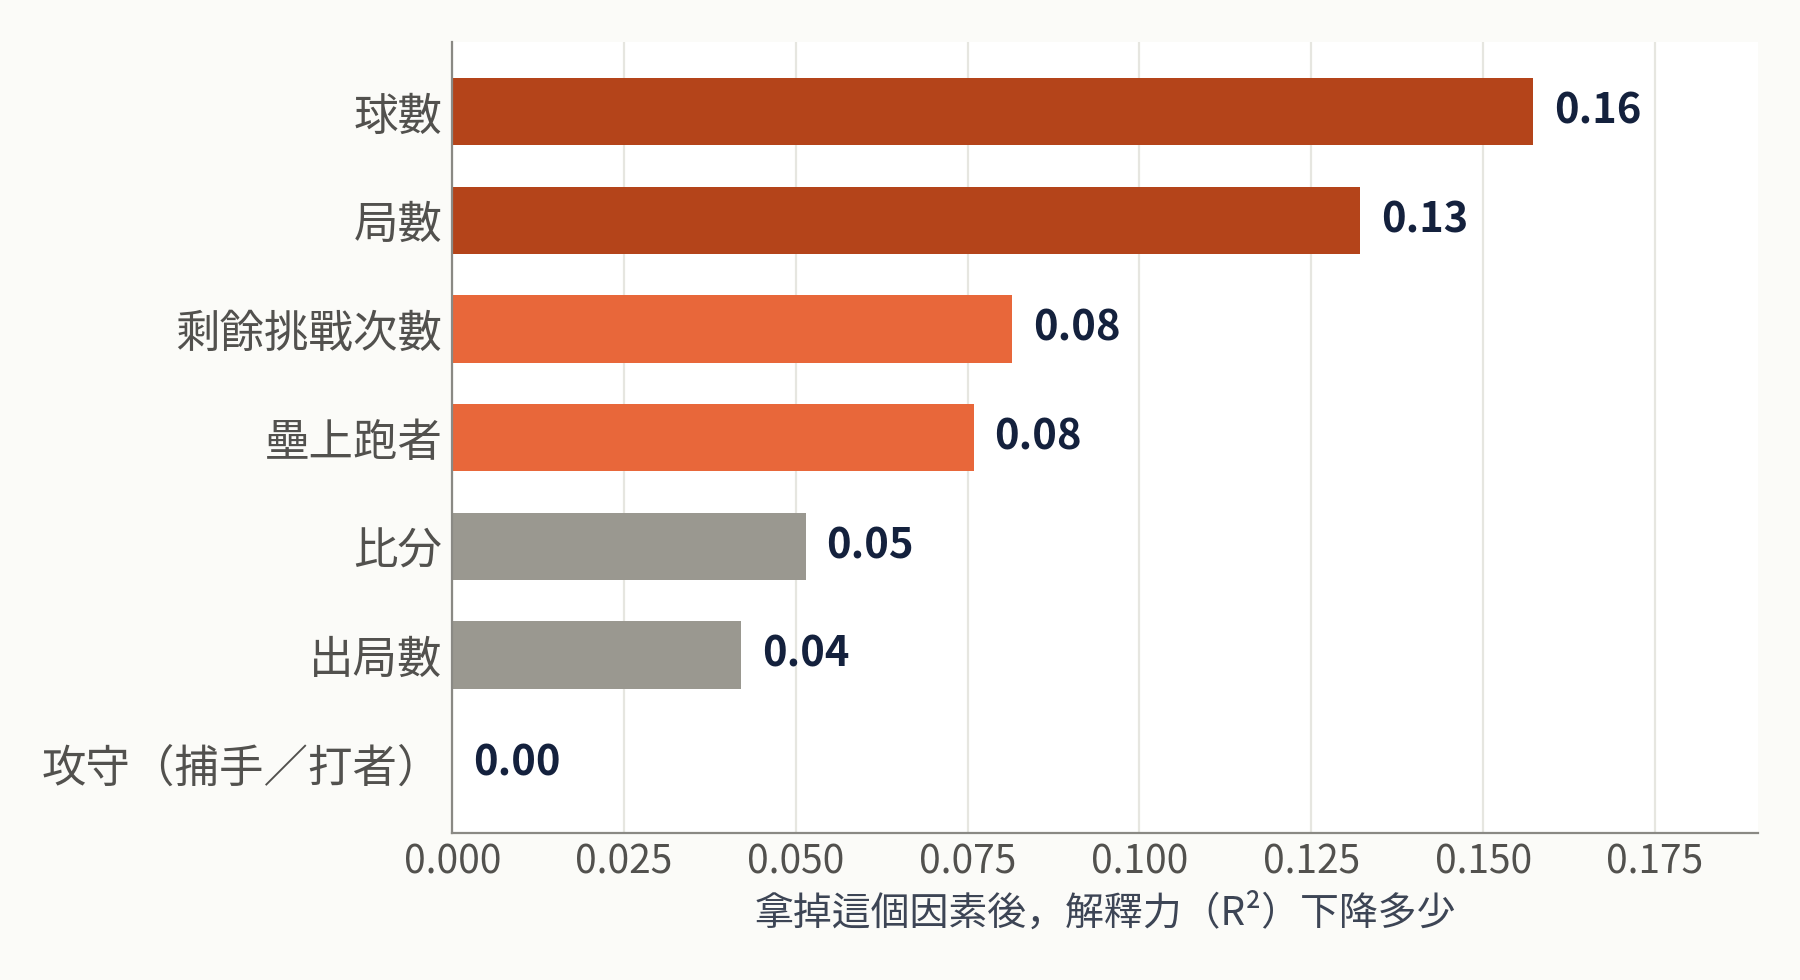

In [23]:
imp = T("pstar_importance")
print(imp.round(3).to_string(index=False))
check(27, "七個因素一起的 R²（約一半）", "0.49", imp["全模型R2"].iloc[0], "{:.2f}")
mg = T("pstar_marginals").set_index(["因素", "類別"])["p*"]
for key, s in [(("球數", "一般"), "45%"), (("球數", "3-2"), "12%"), (("局數", "1-3"), "46%"), (("局數", "9"), "12%"),
               (("剩餘次數", "還有 2 次"), "37%"), (("剩餘次數", "只剩 1 次"), "54%"), (("壘況", "滿壘"), "17%"),
               (("壘況", "壘上無人"), "43%"), (("比分（9 局）", "差 1 分以內"), "10%"),
               (("比分（9 局）", "差 4 分以上"), "23%")]:
    check(27, "／".join(key), s, mg[key], PCT)
print("前 3 局比分接近／大比分差：", mg[("比分（1-3 局）", "差 1 分以內")].round(2), mg[("比分（1-3 局）", "差 4 分以上")].round(2))
show_fig("slide_p27_importance.png")

## 第 28 頁｜挑戰口訣的吻合度

「保守／中立／積極」對應 p* ≥ 40%／20–40%／< 20%。口訣（局數＋例外）和每個決策點的最佳態度相同的比例。

In [24]:
print(T("rule_accuracy").round(3).to_string(index=False))

  剩餘次數        規則    吻合  比最佳保守  比最佳積極
還有 2 次      只看局數 0.520  0.379  0.100
還有 2 次 口訣（局數＋例外） 0.618  0.235  0.147
只剩 1 次      只看局數 0.713  0.258  0.029
只剩 1 次 口訣（局數＋例外） 0.731  0.215  0.055


## 第 29 頁｜給中職球團

In [25]:
r46 = cells[(cells.side == "off") & (cells.ig == "4-6") & (cells.k == 2) & cells.cgrp.str.startswith("b")].iloc[0]
check(29, "4–6 局打者有利球數：實際", "47%", r46.tau, PCT)
check(29, "4–6 局打者有利球數：最佳", "27%", r46.pstar, PCT)
check(29, "捕手每幾次明顯誤判漏看 1 次", "7", 1 / (1 - lam["def"]), "{:.0f}")

[第 29 頁] 4–6 局打者有利球數：實際：簡報 47%｜重算 47% ✓
[第 29 頁] 4–6 局打者有利球數：最佳：簡報 27%｜重算 27% ✓
[第 29 頁] 捕手每幾次明顯誤判漏看 1 次：簡報 7｜重算 7 ✓


## 第 30 頁｜結論與研究限制

In [26]:
fw = T("h2b_forward")
r9f = fw[(fw.by == "ig") & (fw.group == "9")].iloc[0]
check(30, "第 9 局挑戰成功率：模型", "46%", r9f.actual_model_success, PCT)
check(30, "第 9 局挑戰成功率：實際", "40.5%", r9f.actual_success, PCT1)
sens = T("dp_sensitivity").set_index("spec")
check(30, "誤差 1.5 倍時的最佳", "3.4", sens.loc["sigma×1.5", "opt"], "{:.1f}")
check(30, "誤差 1.5 倍時的實際", "3.4", sens.loc["sigma×1.5", "actual"], "{:.1f}")

[第 30 頁] 第 9 局挑戰成功率：模型：簡報 46%｜重算 46% ✓
[第 30 頁] 第 9 局挑戰成功率：實際：簡報 40.5%｜重算 40.5% ✓
[第 30 頁] 誤差 1.5 倍時的最佳：簡報 3.4｜重算 3.4 ✓
[第 30 頁] 誤差 1.5 倍時的實際：簡報 3.4｜重算 3.4 ✓


## 對照總表

`✓`：重算後的四捨五入和簡報完全相同。`≈`：寫法不同（例如簡報四捨五入到不同位數、符號寫法不同），請看兩欄的值。

In [27]:
summary = pd.DataFrame(CHECKS)
print(f"共 {len(summary)} 項，完全一致 {(summary.一致 == '✓').sum()} 項")
summary

共 151 項，完全一致 147 項


,頁,項目,簡報,重算,一致
0,4,全季挑戰次數,"10,558","10,558",✓
1,4,每隊每場挑戰,2.2,2.2,✓
2,4,挑戰成功率,54%,54%,✓
3,4,主審判錯的挑戰機會,"22,623","22,623",✓
4,4,判錯的球實際被挑戰,25%,25%,✓
...,...,...,...,...,...
146,29,捕手每幾次明顯誤判漏看 1 次,7,7,✓
147,30,第 9 局挑戰成功率：模型,46%,46%,✓
148,30,第 9 局挑戰成功率：實際,40.5%,40.5%,✓
149,30,誤差 1.5 倍時的最佳,3.4,3.4,✓
